In [43]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2

## Hồng Gấm – Demo 1: Ảnh là bảng số


**Nguồn ảnh:** https://github.com/opencv/opencv/blob/master/samples/data/baboon.jpg

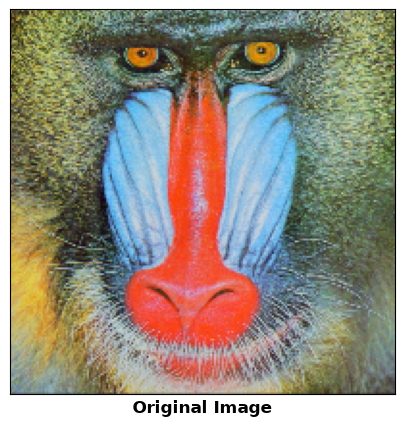

In [44]:
img = cv2.imread("../images/baboon.jpg")

if img is None:
    raise FileNotFoundError("Không tìm thấy baboon.jpg")

img = cv2.resize(img, (200, 200))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.xlabel("Original Image", fontsize=12, fontweight="bold")
plt.xticks([])
plt.yticks([])
plt.show()

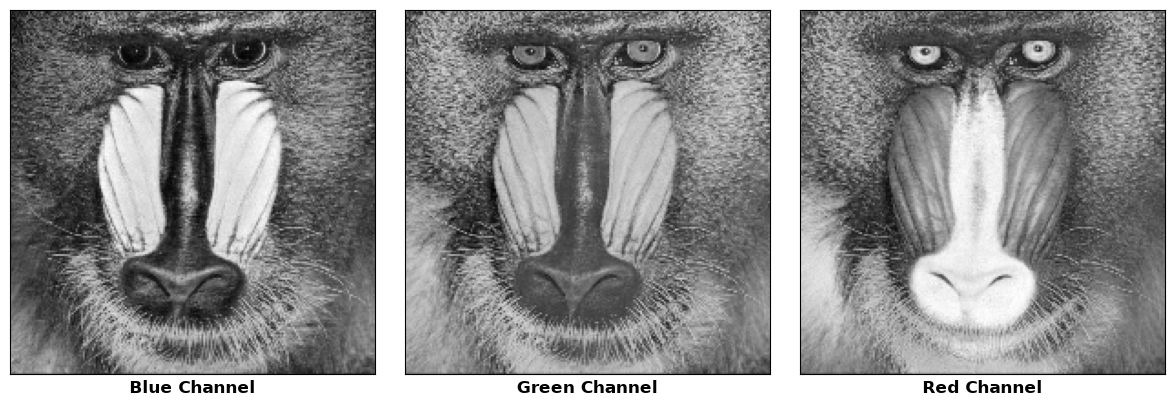

In [45]:
B, G, R = cv2.split(img)

channels = [B, G, R]
labels = ["Blue Channel", "Green Channel", "Red Channel"]

plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(channels[i], cmap="gray", vmin=0, vmax=255)
    plt.xlabel(labels[i], fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

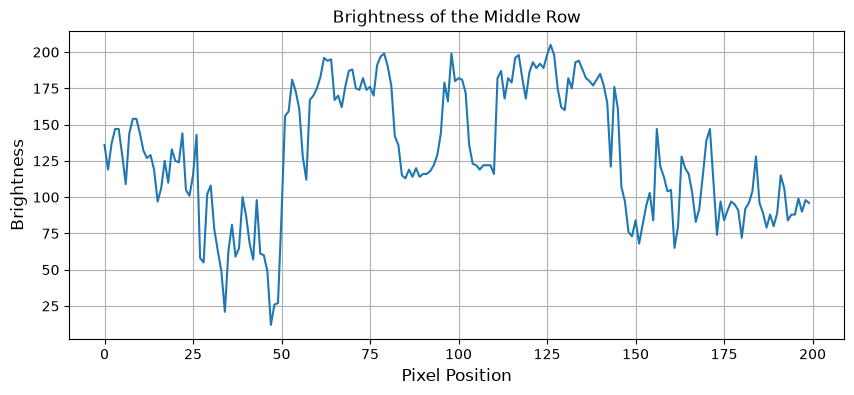

In [46]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

row = gray.shape[0] // 2

plt.figure(figsize=(10, 4))
plt.plot(gray[row, :])

plt.xlabel("Pixel Position", fontsize=12)
plt.ylabel("Brightness", fontsize=12)
plt.title("Brightness of the Middle Row")

plt.grid(True)
plt.show()

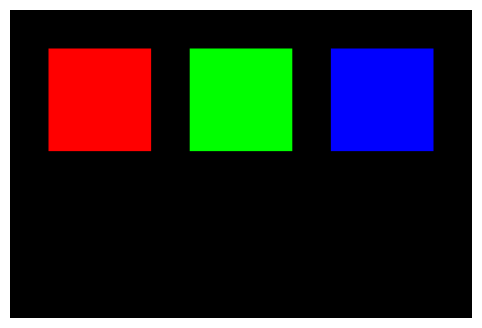

In [47]:

color_img = np.zeros((240, 360, 3), dtype=np.uint8)

color_img[30:110, 30:110] = (0, 0, 255)
color_img[30:110, 140:220] = (0, 255, 0)
color_img[30:110, 250:330] = (255, 0, 0)

plt.figure(figsize=(8, 4))
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

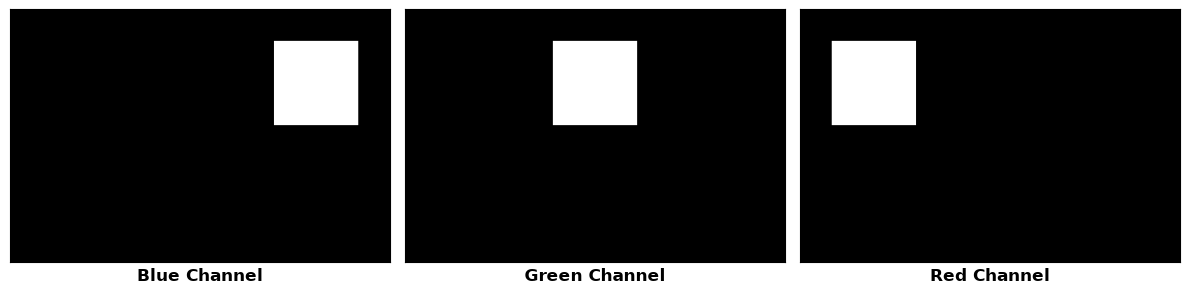

In [48]:

cB, cG, cR = cv2.split(color_img)

plt.figure(figsize=(12, 3))

for i, (ch, label) in enumerate(zip([cB, cG, cR], ["Blue Channel", "Green Channel", "Red Channel"])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(ch, cmap="gray", vmin=0, vmax=255)
    plt.xlabel(label, fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

## Demo 3a: convolve2d, lọc hộp, Gaussian

In [49]:
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

In [50]:

test_image = np.arange(1, 26, dtype=np.float64).reshape(5, 5)

test_kernel = np.array([
    [1, 2, 3],
    [0, 4, 5],
    [6, 7, 8]
], dtype=np.float64) / 36

border_types = {
    "constant": cv2.BORDER_CONSTANT,
    "reflect": cv2.BORDER_REFLECT_101,
    "edge": cv2.BORDER_REPLICATE
}

for padding, border in border_types.items():
    custom_result = convolve2d(
        test_image,
        test_kernel,
        padding
    )

    opencv_result = cv2.filter2D(
        test_image,
        ddepth=-1,
        kernel=np.flip(test_kernel, axis=(0, 1)),
        borderType=border
    )

    max_error = np.max(
        np.abs(custom_result - opencv_result)
    )

    print(f"{padding}: max error = {max_error:.12f}")

constant: max error = 0.000000000000
reflect: max error = 0.000000000000
edge: max error = 0.000000000000


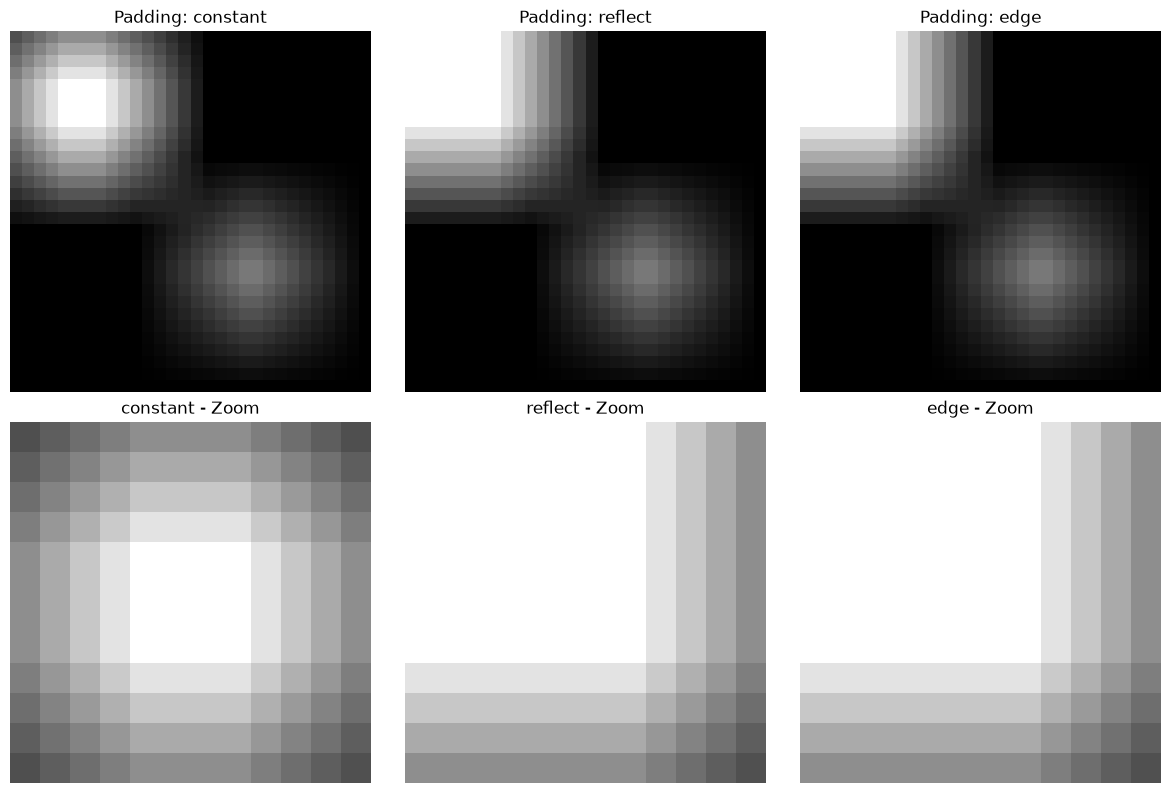

In [51]:

test_img = np.zeros((30, 30), dtype=np.float64)
test_img[:12, :12] = 255
test_img[15:25, 15:25] = 120

kernel = np.ones((9, 9), dtype=np.float64) / 81

results = {
    mode: convolve2d(test_img, kernel, mode)
    for mode in ("constant", "reflect", "edge")
}

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for col, (mode, result) in enumerate(results.items()):
    axes[0, col].imshow(
        result,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, col].set_title(f"Padding: {mode}")
    axes[0, col].axis("off")

    axes[1, col].imshow(
        result[:12, :12],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axes[1, col].set_title(f"{mode} - Zoom")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

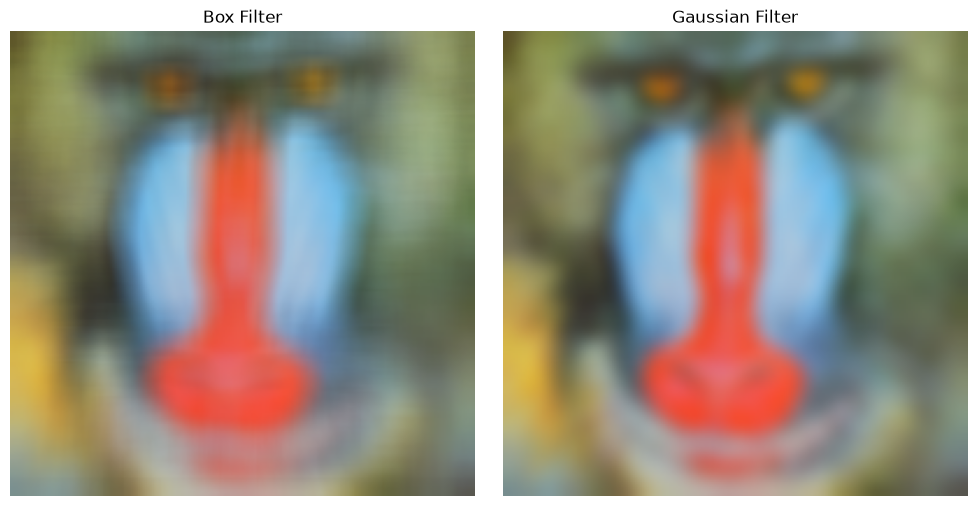

In [52]:

box_kernel = np.ones((15, 15), dtype=np.float64) / 225

g = cv2.getGaussianKernel(15, 4)
gaussian_kernel = g @ g.T

box_channels = [
    convolve2d(img[:, :, c], box_kernel, "reflect")
    for c in range(3)
]

gaussian_channels = [
    convolve2d(img[:, :, c], gaussian_kernel, "reflect")
    for c in range(3)
]

box_blur = np.clip(
    np.round(cv2.merge(box_channels)), 0, 255
).astype(np.uint8)

gaussian_blur = np.clip(
    np.round(cv2.merge(gaussian_channels)), 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(box_blur, cv2.COLOR_BGR2RGB))
axes[0].set_title("Box Filter")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(gaussian_blur, cv2.COLOR_BGR2RGB))
axes[1].set_title("Gaussian Filter")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [53]:

opencv_box = cv2.blur(img, (15, 15), borderType=cv2.BORDER_REFLECT_101)
opencv_gaussian = cv2.GaussianBlur(img, (15, 15), 4, borderType=cv2.BORDER_REFLECT_101)

box_error = np.max(np.abs(box_blur.astype(int) - opencv_box.astype(int)))
gaussian_error = np.max(np.abs(gaussian_blur.astype(int) - opencv_gaussian.astype(int)))

print(f"Box filter vs cv2.blur: max error = {box_error}")
print(f"Gaussian vs cv2.GaussianBlur: max error = {gaussian_error}")

Box filter vs cv2.blur: max error = 0
Gaussian vs cv2.GaussianBlur: max error = 1


In [54]:

cv2.imwrite("../images/box_blur.jpg", box_blur)
cv2.imwrite("../images/gaussian_blur.jpg", gaussian_blur)

True

## KT3 – Thí nghiệm Hough

In [55]:
def create_line_image(rho0, theta0, length, size=400):
    image = np.zeros((size, size), dtype=np.uint8)
    theta = np.deg2rad(theta0)

    direction = np.array([-np.sin(theta), np.cos(theta)])
    points = []

    for x in (0, size - 1):
        if abs(np.sin(theta)) > 1e-10:
            y = (rho0 - x * np.cos(theta)) / np.sin(theta)
            if 0 <= y <= size - 1:
                points.append(np.array([x, y]))

    for y in (0, size - 1):
        if abs(np.cos(theta)) > 1e-10:
            x = (rho0 - y * np.sin(theta)) / np.cos(theta)
            if 0 <= x <= size - 1:
                points.append(np.array([x, y]))

    if len(points) < 2:
        raise ValueError("Đường thẳng không đi qua ảnh")

    points = np.array(points)
    projections = points @ direction

    start = points[np.argmin(projections)]
    end = points[np.argmax(projections)]

    available_length = np.linalg.norm(end - start)

    if length <= 0 or length > available_length:
        raise ValueError("Độ dài vượt quá phần đường thẳng nằm trong ảnh")

    center = (start + end) / 2

    p1 = center - direction * length / 2
    p2 = center + direction * length / 2

    p1 = tuple(np.rint(p1).astype(int))
    p2 = tuple(np.rint(p2).astype(int))

    cv2.line(image, p1, p2, 255, 1)

    return image

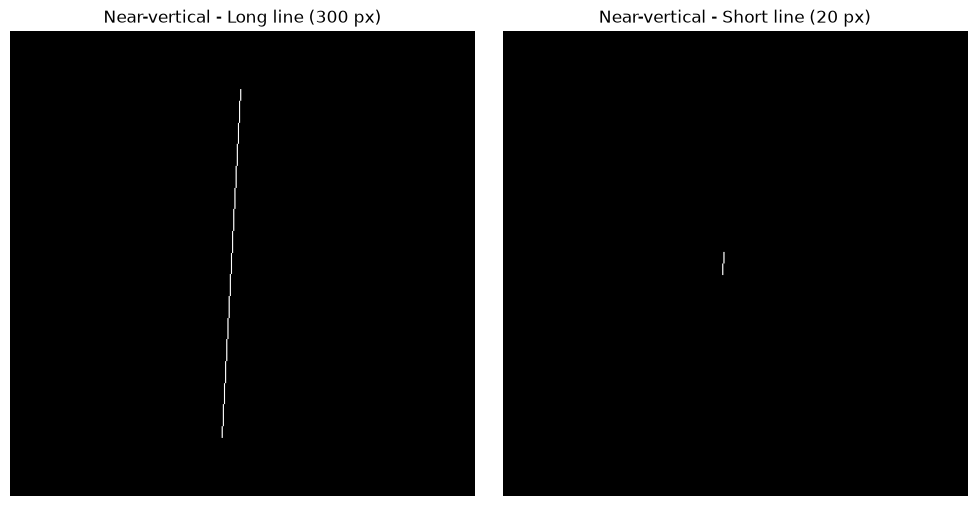

rho0 = 200
theta0 = 3°


In [56]:
rho0 = 200
theta0 = 3

long_image = create_line_image(rho0, theta0, 300)
short_image = create_line_image(rho0, theta0, 20)

cv2.imwrite("../images/hough_long.png", long_image)
cv2.imwrite("../images/hough_short.png", short_image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(long_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Near-vertical - Long line (300 px)")
axes[0].axis("off")

axes[1].imshow(short_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Near-vertical - Short line (20 px)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"rho0 = {rho0}")
print(f"theta0 = {theta0}°")

In [57]:
def angle_error(theta_true, theta_detected):
    difference = abs(theta_true - theta_detected) % 180
    return min(difference, 180 - difference)

print("Test 1:", angle_error(3, 5), "degrees")
print("Test 2:", angle_error(179, 1), "degrees")
print("Test 3:", angle_error(3, 3), "degrees")

Test 1: 2 degrees
Test 2: 2 degrees
Test 3: 0 degrees


In [58]:
lines = cv2.HoughLines(long_image, 1, np.pi / 180, 100)

if lines is None:
    print("Không phát hiện được đường thẳng")
else:
    candidates = []

    for line in lines:
        rho, theta = line[0]
        theta_deg = np.rad2deg(theta)
        error = angle_error(theta0, theta_deg)
        candidates.append((error, rho, theta_deg))

    error, rho_detected, theta_detected = min(candidates)

    print(f"Theta đặt trước: {theta0:.2f}°")
    print(f"Theta phát hiện: {theta_detected:.2f}°")
    print(f"Sai số góc: {error:.2f}°")

Theta đặt trước: 3.00°
Theta phát hiện: 3.00°
Sai số góc: 0.00°
